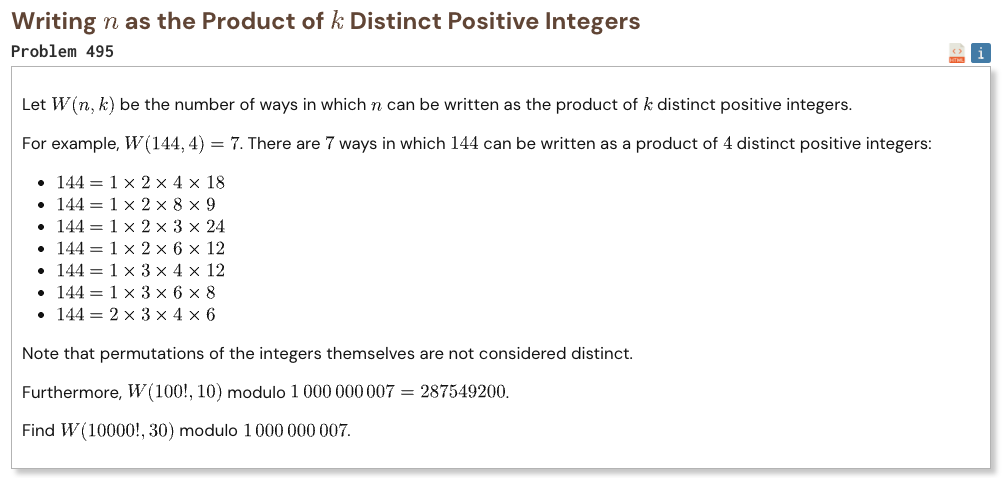

## Initial approach

- factor the factorial into prime powers
- count ordered factorizations first because prime exponents can be distributed independently
- use integer partitions of 30 to describe which factors are forced to be equal
- for each partition count valid exponent distributions with a small dynamic program
- use inclusion exclusion to remove every factorization containing equal factors
- divide out the ordering automatically through the partition weights
- keep every calculation modulo 1000000007

In [1]:
%%time

MOD = 1_000_000_007
N = 10_000
K = 30

def primes_up_to(n):
    sieve = bytearray(b"\x01") * (n + 1)
    sieve[0] = sieve[1] = 0

    p = 2

    while p * p <= n:
        if sieve[p]:
            for x in range(p * p, n + 1, p):
                sieve[x] = 0

        p += 1

    return [
        i
        for i in range(2, n + 1)
        if sieve[i]
    ]

def factorial_exponents(n):
    exponents = []

    for p in primes_up_to(n):
        exponent = 0
        power = p

        while power <= n:
            exponent += n // power
            power *= p

        exponents.append(exponent)

    return exponents

def partitions(n, maximum=None):
    if n == 0:
        yield ()
        return

    if maximum is None or maximum > n:
        maximum = n

    for first in range(maximum, 0, -1):
        for rest in partitions(n - first, first):
            yield (first,) + rest

def partition_weight(parts):
    counts = {}

    for part in parts:
        counts[part] = counts.get(part, 0) + 1

    z = 1

    for part, count in counts.items():
        z *= part ** count

        for i in range(2, count + 1):
            z *= i

    sign = -1 if (K - len(parts)) % 2 else 1

    return sign * pow(z, MOD - 2, MOD)

exponents = factorial_exponents(N)
max_exponent = max(exponents)

frequency = {}

for exponent in exponents:
    frequency[exponent] = frequency.get(exponent, 0) + 1

result = 0

for parts in partitions(K):
    dp = [0] * (max_exponent + 1)
    dp[0] = 1

    for part in parts:
        for exponent in range(part, max_exponent + 1):
            dp[exponent] += dp[exponent - part]

            if dp[exponent] >= MOD:
                dp[exponent] -= MOD

    ways = 1

    for exponent, count in frequency.items():
        ways *= pow(dp[exponent], count, MOD)
        ways %= MOD

    result += partition_weight(parts) * ways
    result %= MOD

print("Result:", result)

Result: 789107601
CPU times: user 1min 1s, sys: 230 ms, total: 1min 1s
Wall time: 1min 2s
